# Mô hình hóa: Hồi quy dự báo giá nhà (`SalePrice`)

**Dữ liệu:** `cleaned.csv` – bộ dữ liệu giá nhà Ames, Iowa (1460 dòng, 81 cột), đã làm sạch.
**Bài toán:** hồi quy – dự báo `SalePrice` (USD) từ đặc điểm của căn nhà.

**Kế thừa từ notebook EDA** (`EDA_Correlation_SalePrice.ipynb`), mô hình hóa áp dụng các phát hiện sau:

| Phát hiện từ EDA | Cách áp dụng trong notebook này |
|---|---|
| `SalePrice` lệch phải mạnh, log làm phân phối gần chuẩn | Huấn luyện trên `log1p(SalePrice)`, đánh giá lại trên thang USD |
| 2 outlier `Partial` (`GrLivArea` > 4000, giá < 300k) | Loại bỏ trước khi chia train/test |
| Biến chất lượng dạng chữ (`Po < Fa < TA < Gd < Ex`, "NoXxx" = 0) | Mã hóa thứ bậc 0–5 (mở rộng cho các biến thứ bậc khác) |
| Các biến diện tích đa cộng tuyến | Tạo `TotalSF`; dùng mô hình có regularization (Ridge/Lasso/ElasticNet) và mô hình cây |
| Có tương tác diện tích × chất lượng | Thêm `OverallQual × GrLivArea`, `OverallQual × TotalSF` |
| Không nên log hóa máy móc biến có nhiều giá trị 0 | Chỉ log hóa biến lệch (skew > 0.75), không âm, không phải nhị phân – và **chỉ học ngưỡng này trên tập train** |

**Quy trình:** chuẩn bị dữ liệu → chia train/test → so sánh nhiều mô hình bằng cross-validation → tinh chỉnh siêu tham số → ensemble → đánh giá cuối cùng **một lần** trên tập test → chẩn đoán sai số & diễn giải → lưu mô hình.

## 1. Import thư viện & cấu hình

In [24]:
import os, warnings, time, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error)

SEED = 42
np.random.seed(SEED)

DATA_PATH = "../data/processed/cleaned.csv"

FIG_OUT = "../reports/figures/"      # thư mục lưu hình
OUT_DIR = "../reports/outputs/"      # thư mục lưu mô hình & bảng kết quả
os.makedirs(FIG_OUT, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.options.display.float_format = "{:,.4f}".format

usd = plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k")   # định dạng trục giá (nghìn USD)

def savefig(name):
    plt.savefig(os.path.join(FIG_OUT, name), dpi=130, bbox_inches="tight")

Pipeline dùng một transformer tự định nghĩa (`LogSkewed`) để log hóa các biến lệch **dựa trên thống kê của tập train** (tránh rò rỉ dữ liệu). Class được ghi ra file `custom_transformers.py` để mô hình lưu bằng `joblib` có thể nạp lại ở nơi khác.

In [2]:
%%writefile custom_transformers.py
import numpy as np
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin


class LogSkewed(BaseEstimator, TransformerMixin):
    # Áp dụng log1p cho các cột: lệch phải (skew > threshold), không âm, và không phải biến nhị phân.
    # Danh sách cột được xác định ở fit() -> chỉ dùng thông tin của tập train.
    def __init__(self, threshold=0.75):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        skew = np.nan_to_num(stats.skew(X, axis=0, nan_policy="omit"))
        n_unique = np.array([len(np.unique(X[:, j])) for j in range(X.shape[1])])
        self.mask_ = (skew > self.threshold) & (X.min(axis=0) >= 0) & (n_unique > 2)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        X[:, self.mask_] = np.log1p(X[:, self.mask_])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

Overwriting custom_transformers.py


In [3]:
from custom_transformers import LogSkewed

## 2. Đọc dữ liệu

> **Lưu ý khi đọc CSV:** pandas mặc định coi chuỗi `"None"` và `"NA"` là giá trị thiếu. Trong file này `"None"` là **một hạng mục có nghĩa** (vd. `MasVnrType = None` = không ốp gạch/đá; `MiscFeature = None` = không có tiện ích khác), nên phải đọc với `keep_default_na=False`. Chỉ ô rỗng và `"NA"` mới là thiếu thật (chỉ 1–8 ô mỗi cột + `GarageYrBlt` của nhà không có garage).

In [4]:
raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["", "NA"])
print("Nguồn dữ liệu:", DATA_PATH)
print("Kích thước:", raw.shape)

miss = raw.isna().sum()
print("\nCác cột còn giá trị thiếu thật sự:")
print(miss[miss > 0].to_string())
raw.head()

Nguồn dữ liệu: ../data/processed/cleaned.csv
Kích thước: (1460, 81)

Các cột còn giá trị thiếu thật sự:
MasVnrType      8
Electrical      1
GarageYrBlt    81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65,8450,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80,9600,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68,11250,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60,9550,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84,14260,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,None,0,12,2008,WD,Normal,250000


## 3. Biến mục tiêu & loại outlier

Theo EDA, 2 căn `Partial` có `GrLivArea` > 4000 sq ft nhưng giá < 300k làm méo quan hệ diện tích–giá. Đây là giao dịch bất thường (nhà chưa hoàn thiện khi bán) nên loại khỏi dữ liệu mô hình.

Số outlier bị loại: 2


,Id,GrLivArea,TotalBsmtSF,OverallQual,SaleCondition,SalePrice
523,524,4676,3138,10,Partial,184750
1298,1299,5642,6110,10,Partial,160000


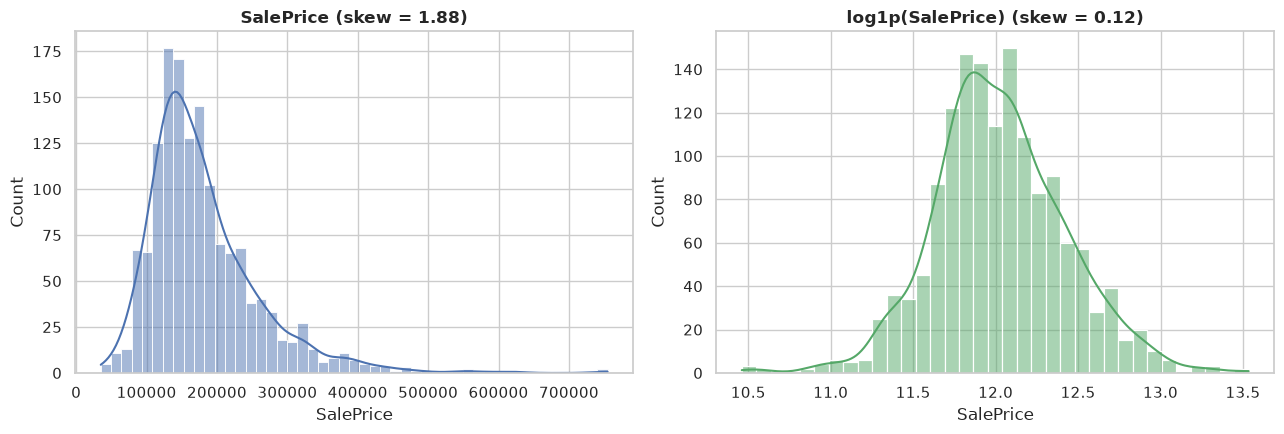

In [5]:
out_mask = (raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000)
print("Số outlier bị loại:", out_mask.sum())
display(raw.loc[out_mask, ["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "SaleCondition", "SalePrice"]])

df = raw.loc[~out_mask].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"SalePrice (skew = {df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="#55A868")
axes[1].set_title(f"log1p(SalePrice) (skew = {np.log1p(df['SalePrice']).skew():.2f})")
plt.tight_layout(); savefig("m01_target.png"); plt.show()

## 4. Tiền xử lý & tạo đặc trưng (feature engineering)

Các phép biến đổi dưới đây là **không trạng thái** (chỉ dựa trên từng dòng, không học gì từ dữ liệu) nên có thể làm trước khi chia train/test mà không gây rò rỉ:

1. **Mã hóa thứ bậc** các biến chất lượng/mức độ (giữ nguyên cách mã hóa của EDA: `Po=1 … Ex=5`, "NoXxx"=0) và các biến thứ bậc khác (`BsmtExposure`, `GarageFinish`, `Functional`, …).
2. **Biến tổng hợp:** `TotalSF`, `TotalBath`, `TotalPorchSF`, `HouseAge`, `RemodAge`, …
3. **Biến tương tác** diện tích × chất lượng (gợi ý từ EDA §6.1).
4. `MSSubClass`, `MoSold` là mã/tháng chứ không phải đại lượng liên tục → chuyển thành biến phân loại.
5. Bỏ `Id`, `GarageYrBlt` (thiếu ở nhà không có garage, trùng thông tin với `YearBuilt`/`HasGarage`), `Utilities` (gần như hằng số).

In [6]:
QUAL = {"NoBasement": 0, "NoGarage": 0, "NoFireplace": 0, "NoPool": 0,
        "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUAL_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
             "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

BSMT_FIN = {"NoBasement": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
ORD_MAPS = {
    "BsmtExposure": {"NoBasement": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": BSMT_FIN,
    "BsmtFinType2": BSMT_FIN,
    "GarageFinish": {"NoGarage": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},
    "CentralAir":   {"N": 0, "Y": 1},
}

def engineer(d):
    d = d.copy()

    # 1) mã hóa thứ bậc
    for c in QUAL_COLS:
        d[c] = d[c].map(QUAL)
    for c, m in ORD_MAPS.items():
        d[c] = d[c].map(m)

    # 2) biến tổng hợp
    d["TotalSF"]       = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    d["TotalBath"]     = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"]
    d["TotalPorchSF"]  = d["OpenPorchSF"] + d["EnclosedPorch"] + d["3SsnPorch"] + d["ScreenPorch"]
    d["HouseAge"]      = (d["YrSold"] - d["YearBuilt"]).clip(lower=0)
    d["RemodAge"]      = (d["YrSold"] - d["YearRemodAdd"]).clip(lower=0)
    d["IsRemodeled"]   = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)
    d["IsNewHouse"]    = (d["YrSold"] == d["YearBuilt"]).astype(int)
    d["HasBsmt"]       = (d["TotalBsmtSF"] > 0).astype(int)
    d["Has2ndFlr"]     = (d["2ndFlrSF"] > 0).astype(int)
    d["HasGarage"]     = (d["GarageArea"] > 0).astype(int)
    d["HasFireplace"]  = (d["Fireplaces"] > 0).astype(int)
    d["HasPool"]       = (d["PoolArea"] > 0).astype(int)

    # 3) tương tác diện tích x chất lượng
    d["Qual_x_GrLivArea"] = d["OverallQual"] * d["GrLivArea"]
    d["Qual_x_TotalSF"]   = d["OverallQual"] * d["TotalSF"]

    # 4) biến mã/tháng -> phân loại
    d["MSSubClass"] = d["MSSubClass"].astype(str)
    d["MoSold"]     = d["MoSold"].astype(str)

    # 5) bỏ cột không dùng
    return d.drop(columns=["Id", "GarageYrBlt", "Utilities"])

df_fe = engineer(df)

TARGET = "SalePrice"
X = df_fe.drop(columns=[TARGET])
y = np.log1p(df_fe[TARGET])          # mô hình học trên thang log

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"{X.shape[1]} đặc trưng thô: {len(num_cols)} số + {len(cat_cols)} phân loại")
print("Phân loại:", cat_cols)

91 đặc trưng thô: 66 số + 25 phân loại
Phân loại: ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'Fence', 'MiscFeature', 'MoSold', 'SaleType', 'SaleCondition']


## 5. Chia tập train / test

- **80% train / 20% test**, chia phân tầng theo 5 nhóm giá để cả hai tập có phân phối giá tương tự.
- Tập test **chỉ dùng một lần ở bước 10** để báo cáo hiệu năng cuối cùng; mọi so sánh và tinh chỉnh dùng cross-validation trên tập train.

In [7]:
strata = pd.qcut(y, 5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=strata)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Giá trung vị  train = {np.expm1(y_train).median():,.0f}  |  test = {np.expm1(y_test).median():,.0f}")

Train: (1166, 91) | Test: (292, 91)
Giá trung vị  train = 163,000  |  test = 161,500


## 6. Pipeline tiền xử lý

Hai biến thể (cùng đưa vào `Pipeline` nên mọi bước đều được **fit lại riêng trong từng fold** của CV):

- **Mô hình tuyến tính** (Linear/Ridge/Lasso/ElasticNet): điền thiếu (median) → `log1p` biến lệch → chuẩn hóa → One-Hot (gộp hạng mục hiếm < 10 mẫu vào nhóm "infrequent").
- **Mô hình cây** (RF, GB, HistGB): điền thiếu → One-Hot; không cần log/chuẩn hóa vì cây bất biến với phép biến đổi đơn điệu.

In [8]:
def make_preprocessor(linear=True):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if linear:
        steps += [("log", LogSkewed(threshold=0.75)), ("sc", StandardScaler())]
    num_pipe = Pipeline(steps)

    cat_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=10, sparse_output=False)),
    ])
    return ColumnTransformer([("num", num_pipe, num_cols),
                              ("cat", cat_pipe, cat_cols)],
                             verbose_feature_names_out=False)

def make_pipe(model, linear=True):
    return Pipeline([("prep", make_preprocessor(linear)), ("model", model)])

n_feat = make_preprocessor(True).fit(X_train).get_feature_names_out().shape[0]
print(f"Sau tiền xử lý: {n_feat} đặc trưng đầu vào cho mô hình")

lg = make_preprocessor(True).fit(X_train).named_transformers_["num"].named_steps["log"]
logged = np.array(num_cols)[lg.mask_]
print(f"\n{len(logged)}/{len(num_cols)} biến số được log hóa (học trên train), ví dụ:", [str(c) for c in logged[:10]])

Sau tiền xử lý: 223 đặc trưng đầu vào cho mô hình

28/66 biến số được log hóa (học trên train), ví dụ: ['LotFrontage', 'LotArea', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtExposure', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF']


## 7. So sánh các mô hình bằng cross-validation

- CV **5-fold** có xáo trộn trên tập train.
- Thước đo chính: **RMSE trên thang log** (= RMSLE: sai số tương đối, không để nhà đắt chi phối) và **R²**. Báo cáo thêm MAE theo USD.
- Mô hình `Dummy` (luôn dự báo trung bình) làm mốc tối thiểu; `LinearRegression` thường (OLS) làm baseline tuyến tính.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_eval(name, pipe, store):
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=-1, return_train_score=True,
                       scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    store[name] = {
        "CV RMSLE (log)":  -r["test_rmse"].mean(),
        "± std":            r["test_rmse"].std(),
        "CV R²":            r["test_r2"].mean(),
        "Train RMSLE":     -r["train_rmse"].mean(),
        "Thời gian (s)":    time.time() - t0,
    }

base_models = {
    "Dummy (trung bình)":  (DummyRegressor(), True),
    "Linear Regression":   (LinearRegression(), True),
    "Ridge":               (Ridge(alpha=10, random_state=SEED), True),
    "Lasso":               (Lasso(alpha=0.001, max_iter=50000, random_state=SEED), True),
    "ElasticNet":          (ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=50000, random_state=SEED), True),
    "Random Forest":       (RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                  max_features=0.5, random_state=SEED), False),
    "Gradient Boosting":   (GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                                      subsample=0.8, random_state=SEED), False),
    "HistGradientBoosting":(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05,
                                                          random_state=SEED), False),
}

cv_results = {}
for name, (m, lin) in base_models.items():
    cv_eval(name, make_pipe(m, lin), cv_results)

cv_table = pd.DataFrame(cv_results).T.sort_values("CV RMSLE (log)")
cv_table

,CV RMSLE (log),± std,CV R²,Train RMSLE,Thời gian (s)
ElasticNet,0.1108,0.0090,0.9217,0.0928,0.2272
Lasso,0.1118,0.0075,0.9206,0.0976,0.2064
Ridge,0.1119,0.0088,0.9202,0.0907,0.1889
Gradient Boosting,0.1171,0.0074,0.9142,0.0407,4.0154
Linear Regression,0.1211,0.0087,0.9065,0.0855,1.2667
HistGradientBoosting,0.1252,0.0068,0.9020,0.0191,9.3059
Random Forest,0.1318,0.0072,0.8912,0.0586,3.7580
Dummy (trung bình),0.4020,0.0286,-0.0050,0.4026,2.0332


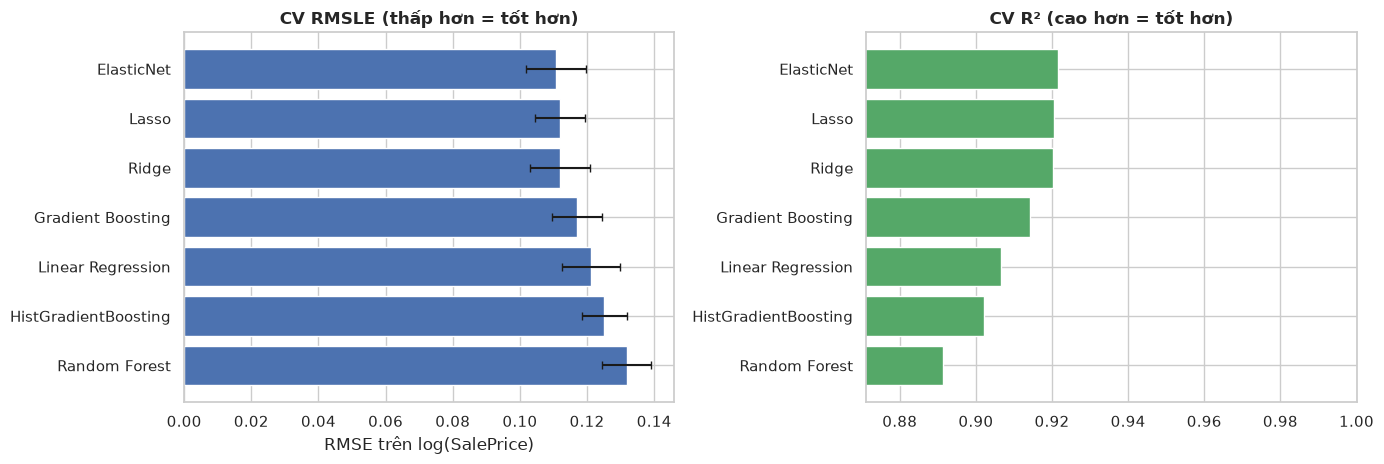

In [10]:
plot_df = cv_table.drop(index="Dummy (trung bình)").sort_values("CV RMSLE (log)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(plot_df.index, plot_df["CV RMSLE (log)"], xerr=plot_df["± std"], color="#4C72B0", capsize=3)
axes[0].set_title("CV RMSLE (thấp hơn = tốt hơn)"); axes[0].set_xlabel("RMSE trên log(SalePrice)")
axes[1].barh(plot_df.index, plot_df["CV R²"], color="#55A868")
axes[1].set_xlim(plot_df["CV R²"].min() - 0.02, 1); axes[1].set_title("CV R² (cao hơn = tốt hơn)")
plt.tight_layout(); savefig("m02_cv_baseline.png"); plt.show()

> **Cách đọc:** so sánh `CV RMSLE` với `Train RMSLE`. Khoảng cách lớn (train ≪ CV) là dấu hiệu **overfit** – thấy rõ ở Random Forest, Gradient Boosting và HistGradientBoosting chưa tinh chỉnh. Các mô hình tuyến tính có regularization (Ridge/Lasso/ElasticNet) vừa ít overfit hơn vừa xử lý được đa cộng tuyến mà EDA đã cảnh báo, nên đạt CV RMSLE thấp nhất trước khi tinh chỉnh.

## 8. Tinh chỉnh siêu tham số

- Mô hình tuyến tính có regularization: `GridSearchCV` trên lưới `alpha` (và `l1_ratio` cho ElasticNet).
- Mô hình boosting: `RandomizedSearchCV` (12 tổ hợp).
- Dùng cùng 5-fold CV; điểm CV của mô hình đã tinh chỉnh hơi lạc quan (chọn tham số tốt nhất trên chính các fold) – vì vậy tập test ở bước 10 mới là thước đo trung thực.

In [11]:
tuned = {}      # tên -> pipeline đã tinh chỉnh (chưa fit lại)
search_log = {}

def run_search(name, search):
    t0 = time.time()
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    search_log[name] = {"CV RMSLE": -search.best_score_, "Tham số tốt nhất":
                        {k.replace("model__", ""): (round(v, 5) if isinstance(v, float) else v)
                         for k, v in search.best_params_.items()},
                        "Thời gian (s)": round(time.time() - t0, 1)}

common = dict(cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)

run_search("Ridge", GridSearchCV(
    make_pipe(Ridge(random_state=SEED)),
    {"model__alpha": np.logspace(-1, 2.5, 25)}, **common))

run_search("Lasso", GridSearchCV(
    make_pipe(Lasso(max_iter=50000, random_state=SEED)),
    {"model__alpha": np.logspace(-4, -1.5, 25)}, **common))

run_search("ElasticNet", GridSearchCV(
    make_pipe(ElasticNet(max_iter=50000, random_state=SEED)),
    {"model__alpha": np.logspace(-4, -1.5, 10),
     "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}, **common))

run_search("Gradient Boosting", RandomizedSearchCV(
    make_pipe(GradientBoostingRegressor(random_state=SEED), linear=False),
    {"model__n_estimators":   [300, 500, 800],
     "model__learning_rate":  [0.02, 0.03, 0.05],
     "model__max_depth":      [2, 3, 4],
     "model__min_samples_leaf": [3, 5, 10, 15],
     "model__subsample":      [0.6, 0.8, 1.0],
     "model__max_features":   [0.3, 0.6]},
    n_iter=12, random_state=SEED, **common))

run_search("HistGradientBoosting", RandomizedSearchCV(
    make_pipe(HistGradientBoostingRegressor(random_state=SEED), linear=False),
    {"model__max_iter":          [300, 500],
     "model__learning_rate":     [0.02, 0.03, 0.05],
     "model__max_leaf_nodes":    [8, 15, 31],
     "model__min_samples_leaf":  [5, 10, 20],
     "model__l2_regularization": [0, 0.1, 1.0, 10.0]},
    n_iter=12, random_state=SEED, **common))

pd.DataFrame(search_log).T

,CV RMSLE,Tham số tốt nhất,Thời gian (s)
Ridge,0.1117,{'alpha': 15.39927},2.6000
Lasso,0.1109,{'alpha': 0.00054},6.8000
ElasticNet,0.1108,"{'alpha': 0.00464, 'l1_ratio': 0.1}",24.1000
Gradient Boosting,0.1148,"{'subsample': 0.6, 'n_estimators': 800, 'min_s...",22.0000
HistGradientBoosting,0.1195,"{'min_samples_leaf': 5, 'max_leaf_nodes': 15, ...",104.4000


### 8.1 Ensemble

Trung bình dự báo của các mô hình khác nhau về bản chất (tuyến tính có regularization + boosting) thường cho sai số thấp hơn từng mô hình riêng lẻ, vì lỗi của chúng không hoàn toàn trùng nhau.

In [12]:
ens = VotingRegressor([(n, clone(p)) for n, p in tuned.items()
                       if n in ["Lasso", "ElasticNet", "Gradient Boosting", "HistGradientBoosting"]])
tuned["Ensemble (Voting)"] = ens

final_cv = {}
for name, pipe in tuned.items():
    cv_eval(name + " (tuned)" if name != "Ensemble (Voting)" else name, pipe, final_cv)

compare = pd.concat([cv_table.loc[["Dummy (trung bình)", "Linear Regression"]], pd.DataFrame(final_cv).T])
compare = compare.sort_values("CV RMSLE (log)")
compare

,CV RMSLE (log),± std,CV R²,Train RMSLE,Thời gian (s)
Ensemble (Voting),0.1085,0.0065,0.9255,0.0696,11.2262
ElasticNet (tuned),0.1108,0.0086,0.9219,0.0937,0.3168
Lasso (tuned),0.1109,0.0090,0.9216,0.0930,0.3441
Ridge (tuned),0.1117,0.0087,0.9205,0.0923,0.2116
Gradient Boosting (tuned),0.1148,0.0063,0.9171,0.0745,2.1985
HistGradientBoosting (tuned),0.1195,0.0056,0.9104,0.0315,8.5988
Linear Regression,0.1211,0.0087,0.9065,0.0855,1.2667
Dummy (trung bình),0.4020,0.0286,-0.0050,0.4026,2.0332


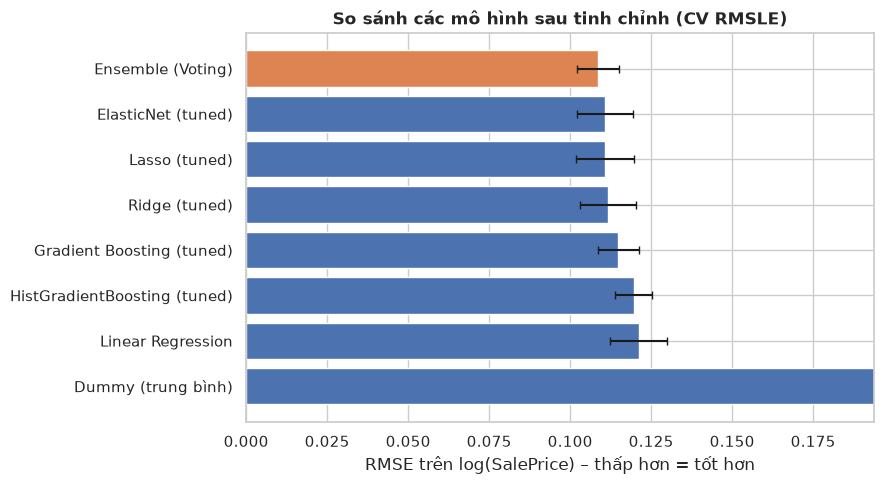

Mô hình tốt nhất theo CV: Ensemble (Voting)


In [13]:
plot_df = compare.sort_values("CV RMSLE (log)", ascending=False)
colors = ["#DD8452" if "Ensemble" in i else "#4C72B0" for i in plot_df.index]
plt.figure(figsize=(9, 5))
plt.barh(plot_df.index, plot_df["CV RMSLE (log)"], xerr=plot_df["± std"], color=colors, capsize=3)
plt.xlim(0, plot_df.drop(index="Dummy (trung bình)")["CV RMSLE (log)"].max() * 1.6)
plt.title("So sánh các mô hình sau tinh chỉnh (CV RMSLE)"); plt.xlabel("RMSE trên log(SalePrice) – thấp hơn = tốt hơn")
plt.tight_layout(); savefig("m03_cv_tuned.png"); plt.show()

best_name = compare.drop(index=["Dummy (trung bình)", "Linear Regression"])["CV RMSLE (log)"].idxmin()
print("Mô hình tốt nhất theo CV:", best_name)

### 8.2 Ablation: diện tích hay chất lượng giải thích giá tốt hơn?

Quay lại câu hỏi nghiên cứu của EDA, nhưng nay đo bằng **sức dự báo ngoài mẫu** (CV R² của hồi quy tuyến tính trên log giá) thay vì hệ số tương quan.

In [14]:
subsets = {
    "Chỉ diện tích (GrLivArea)":                   ["GrLivArea"],
    "Chỉ chất lượng (OverallQual)":                ["OverallQual"],
    "Diện tích + Chất lượng":                      ["GrLivArea", "OverallQual"],
    "Diện tích + Chất lượng + tương tác":          ["GrLivArea", "OverallQual", "Qual_x_GrLivArea"],
    "TotalSF + Chất lượng + tương tác":            ["TotalSF", "OverallQual", "Qual_x_TotalSF"],
    "Nhóm 'cốt lõi' (+ tuổi, garage, bếp, hầm...)": ["TotalSF", "OverallQual", "Qual_x_TotalSF", "GarageCars",
                                                       "KitchenQual", "ExterQual", "BsmtQual", "HouseAge",
                                                       "TotalBath", "Fireplaces", "LotArea"],
}
rows = []
for name, cols in subsets.items():
    pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("log", LogSkewed()),
                     ("sc", StandardScaler()), ("m", LinearRegression())])
    r = cross_validate(pipe, X_train[cols], y_train, cv=cv, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    rows.append({"Bộ biến": name, "Số biến": len(cols),
                 "CV R²": r["test_r2"].mean(), "CV RMSLE": -r["test_rmse"].mean()})
rows.append({"Bộ biến": "Toàn bộ đặc trưng (Lasso đã tinh chỉnh)", "Số biến": X_train.shape[1],
             "CV R²": final_cv["Lasso (tuned)"]["CV R²"], "CV RMSLE": final_cv["Lasso (tuned)"]["CV RMSLE (log)"]})
pd.DataFrame(rows).set_index("Bộ biến")

,Số biến,CV R²,CV RMSLE
Bộ biến,,,
Chỉ diện tích (GrLivArea),1,0.5582,0.2657
Chỉ chất lượng (OverallQual),1,0.6800,0.2254
Diện tích + Chất lượng,2,0.7762,0.1882
Diện tích + Chất lượng + tương tác,3,0.7770,0.1879
TotalSF + Chất lượng + tương tác,3,0.8113,0.1728
"Nhóm 'cốt lõi' (+ tuổi, garage, bếp, hầm...)",11,0.8795,0.1380
Toàn bộ đặc trưng (Lasso đã tinh chỉnh),91,0.9216,0.1109


## 9. Huấn luyện mô hình cuối & đánh giá trên tập test

Mô hình được chọn **tự động theo CV RMSLE thấp nhất** ở bước 8, huấn luyện lại trên toàn bộ tập train, rồi đánh giá **đúng một lần** trên tập test (chưa từng được dùng).

In [15]:
final_model = clone(tuned[best_name]).fit(X_train, y_train)

def metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {
        "RMSLE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "R² (log)":    r2_score(y_true_log, y_pred_log),
        "R² (USD)":    r2_score(yt, yp),
        "RMSE (USD)":  np.sqrt(mean_squared_error(yt, yp)),
        "MAE (USD)":   mean_absolute_error(yt, yp),
        "MAPE (%)":    100 * mean_absolute_percentage_error(yt, yp),
        "Median APE (%)": 100 * np.median(np.abs(yp - yt) / yt),
    }

pred_train = final_model.predict(X_train)
pred_test  = final_model.predict(X_test)

res = pd.DataFrame({"Train": metrics(y_train, pred_train), "Test": metrics(y_test, pred_test)})
print("Mô hình cuối:", best_name)
res

Mô hình cuối: Ensemble (Voting)


,Train,Test
RMSLE (log),0.0727,0.1201
R² (log),0.9674,0.9033
R² (USD),0.9676,0.9384
RMSE (USD),"14,802.1196","16,639.2089"
MAE (USD),"9,607.4542","12,027.4746"
MAPE (%),5.3450,8.1264
Median APE (%),4.1159,5.1614


In [16]:
# Mốc so sánh: mô hình luôn đoán giá trung vị / Lasso / mô hình tốt nhất trên tập test
test_cmp = {}
dummy = make_pipe(DummyRegressor()).fit(X_train, y_train)
test_cmp["Dummy (trung bình)"] = metrics(y_test, dummy.predict(X_test))
for n in ["Ridge", "Lasso", "ElasticNet", "Gradient Boosting", "HistGradientBoosting", "Ensemble (Voting)"]:
    m = clone(tuned[n]).fit(X_train, y_train)
    test_cmp[n + (" (tuned)" if n != "Ensemble (Voting)" else "")] = metrics(y_test, m.predict(X_test))
pd.DataFrame(test_cmp).T.sort_values("RMSLE (log)")

,RMSLE (log),R² (log),R² (USD),RMSE (USD),MAE (USD),MAPE (%),Median APE (%)
Ensemble (Voting),0.1201,0.9033,0.9384,"16,639.2089","12,027.4746",8.1264,5.1614
Lasso (tuned),0.1223,0.8999,0.9293,"17,826.5035","12,824.8789",8.4441,5.4887
Gradient Boosting (tuned),0.1231,0.8985,0.9346,"17,146.7069","12,303.7170",8.3707,5.3392
ElasticNet (tuned),0.1235,0.8978,0.9284,"17,932.7015","12,853.0853",8.4915,5.4032
Ridge (tuned),0.1246,0.8960,0.9276,"18,041.4839","12,805.7946",8.4813,5.0786
HistGradientBoosting (tuned),0.1279,0.8904,0.9299,"17,754.0018","12,930.2637",8.8405,5.7308
Dummy (trung bình),0.3871,-0.0034,-0.0160,"67,568.7254","51,632.8505",33.5649,25.1054


> Bảng trên chỉ để **tham khảo** (cho thấy mô hình chọn theo CV có phải cũng tốt trên test hay không). Không nên chọn lại mô hình theo kết quả test – làm vậy là dùng tập test để tuyển chọn và sẽ làm điểm test trở nên lạc quan.

### 9.1 Dự báo so với thực tế & chẩn đoán phần dư

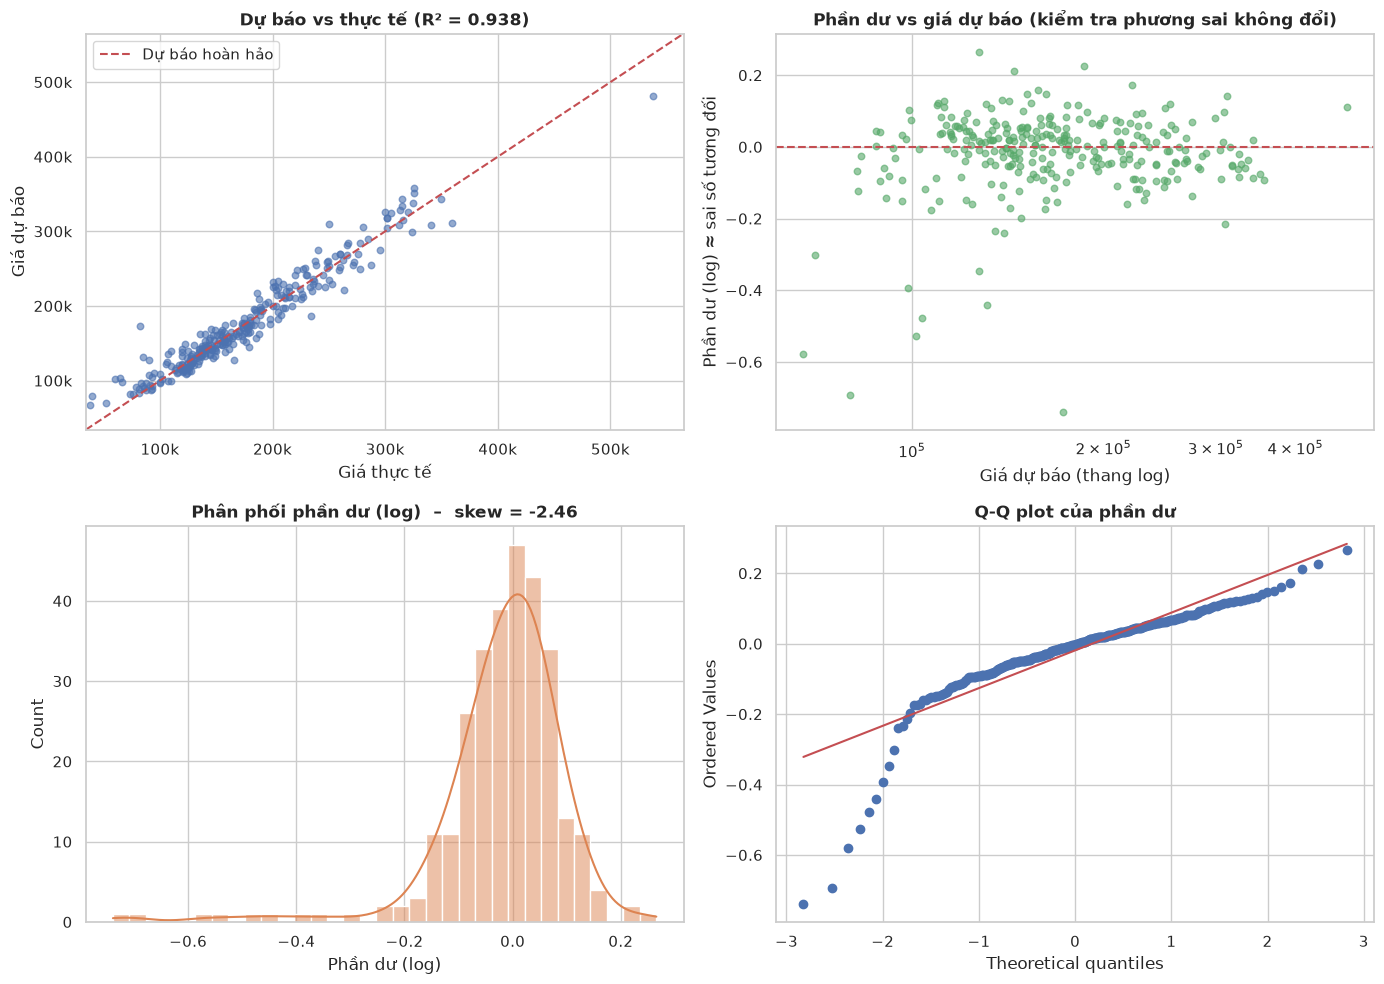

In [17]:
y_true = np.expm1(y_test.values)
y_hat  = np.expm1(pred_test)
resid_log = y_test.values - pred_test          # phần dư trên thang log ≈ sai số tương đối

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.scatter(y_true, y_hat, s=22, alpha=0.6, color="#4C72B0")
lim = [min(y_true.min(), y_hat.min()) * 0.9, max(y_true.max(), y_hat.max()) * 1.05]
ax.plot(lim, lim, "r--", lw=1.5, label="Dự báo hoàn hảo")
ax.set_xlim(lim); ax.set_ylim(lim); ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd)
ax.set_xlabel("Giá thực tế"); ax.set_ylabel("Giá dự báo")
ax.set_title(f"Dự báo vs thực tế (R² = {r2_score(y_true, y_hat):.3f})"); ax.legend()

ax = axes[0, 1]
ax.scatter(y_hat, resid_log, s=22, alpha=0.6, color="#55A868")
ax.axhline(0, color="r", ls="--")
ax.set_xscale("log"); ax.set_xlabel("Giá dự báo (thang log)"); ax.set_ylabel("Phần dư (log) ≈ sai số tương đối")
ax.set_title("Phần dư vs giá dự báo (kiểm tra phương sai không đổi)")

ax = axes[1, 0]
sns.histplot(resid_log, kde=True, ax=ax, color="#DD8452")
ax.set_title(f"Phân phối phần dư (log)  –  skew = {stats.skew(resid_log):.2f}")
ax.set_xlabel("Phần dư (log)")

ax = axes[1, 1]
stats.probplot(resid_log, dist="norm", plot=ax)
ax.set_title("Q-Q plot của phần dư")

plt.tight_layout(); savefig("m04_diagnostics.png"); plt.show()

### 9.2 Sai số theo phân khúc giá & chất lượng

,n,MAE_USD,MAPE,Bias_pct
Phân khúc giá,,,,
Q1 (rẻ nhất),75,"12,280.9691",14.7273,10.5414
Q2,72,"7,633.4767",5.2446,0.6924
Q3,72,"11,655.7711",6.2167,-1.0273
Q4 (đắt nhất),73,"16,467.4527",6.0706,0.3816


,n,MAE_USD,MAPE,Bias_pct
Nhóm chất lượng,,,,
1–4 (thấp),22,"13,082.3045",18.7838,12.2482
5–6 (TB),161,"9,719.7040",7.3718,1.4682
7–8 (khá),99,"15,403.3522",7.3665,2.5117
9–10 (cao),10,"13,440.7665",4.3522,3.9856


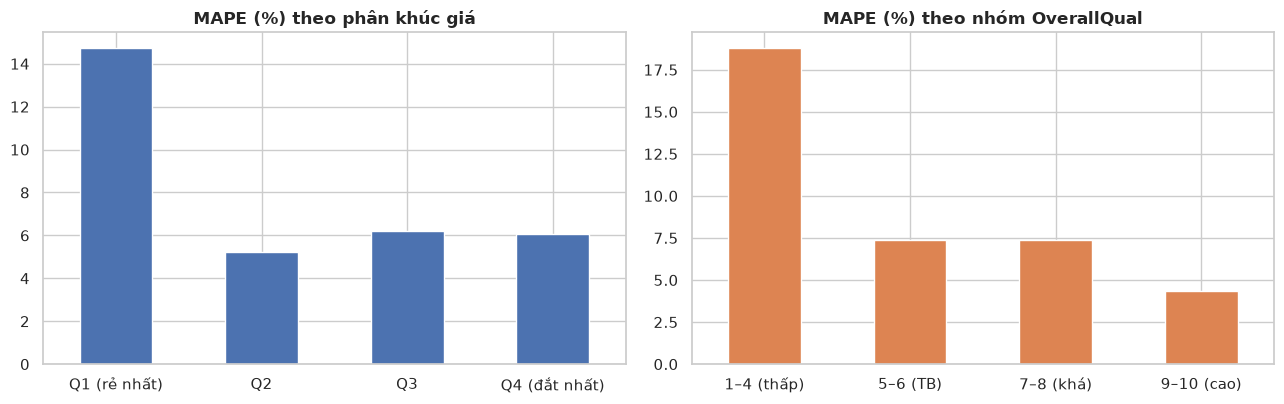

In [18]:
err = pd.DataFrame({"actual": y_true, "pred": y_hat, "OverallQual": X_test["OverallQual"].values})
err["abs_err"] = (err["pred"] - err["actual"]).abs()
err["ape"] = 100 * err["abs_err"] / err["actual"]
err["bias_%"] = 100 * (err["pred"] - err["actual"]) / err["actual"]     # >0: dự báo cao hơn thực tế

err["Phân khúc giá"] = pd.qcut(err["actual"], 4, labels=["Q1 (rẻ nhất)", "Q2", "Q3", "Q4 (đắt nhất)"])
err["Nhóm chất lượng"] = pd.cut(err["OverallQual"], [0, 4, 6, 8, 10],
                                labels=["1–4 (thấp)", "5–6 (TB)", "7–8 (khá)", "9–10 (cao)"])

by_price = err.groupby("Phân khúc giá", observed=True).agg(
    n=("actual", "size"), MAE_USD=("abs_err", "mean"), MAPE=("ape", "mean"), Bias_pct=("bias_%", "mean"))
by_qual = err.groupby("Nhóm chất lượng", observed=True).agg(
    n=("actual", "size"), MAE_USD=("abs_err", "mean"), MAPE=("ape", "mean"), Bias_pct=("bias_%", "mean"))
display(by_price); display(by_qual)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
by_price["MAPE"].plot(kind="bar", ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_title("MAPE (%) theo phân khúc giá"); axes[0].set_xlabel("")
by_qual["MAPE"].plot(kind="bar", ax=axes[1], color="#DD8452", rot=0)
axes[1].set_title("MAPE (%) theo nhóm OverallQual"); axes[1].set_xlabel("")
plt.tight_layout(); savefig("m05_error_segments.png"); plt.show()

### 9.3 Các dự báo sai nhiều nhất

In [19]:
worst = X_test.assign(Actual=y_true, Predicted=y_hat.round(0))
worst["Sai số (USD)"] = (worst["Predicted"] - worst["Actual"]).round(0)
worst["Sai số (%)"] = (100 * worst["Sai số (USD)"] / worst["Actual"]).round(1)
worst.reindex(worst["Sai số (%)"].abs().sort_values(ascending=False).index).head(10)[
    ["Neighborhood", "SaleCondition", "OverallQual", "GrLivArea", "YearBuilt",
     "Actual", "Predicted", "Sai số (USD)", "Sai số (%)"]]

,Neighborhood,SaleCondition,OverallQual,GrLivArea,YearBuilt,Actual,Predicted,Sai số (USD),Sai số (%)
631,NWAmes,Family,7,1411,1977,"82,500.0000","172,761.0000","90,261.0000",109.4000
30,IDOTRR,Normal,4,1317,1920,"40,000.0000","80,027.0000","40,027.0000",100.1000
967,OldTown,Abnorml,3,968,1910,"37,900.0000","67,619.0000","29,719.0000",78.4000
410,Edwards,Abnorml,5,1276,1958,"60,000.0000","101,664.0000","41,664.0000",69.4000
1430,OldTown,Normal,4,968,1927,"64,500.0000","103,897.0000","39,397.0000",61.1000
1451,Mitchel,Abnorml,5,1140,2006,"84,500.0000","131,313.0000","46,813.0000",55.4000
873,OldTown,Abnorml,5,1131,1941,"66,500.0000","98,591.0000","32,091.0000",48.3000
1061,OldTown,Normal,5,2337,1900,"90,000.0000","127,369.0000","37,369.0000",41.5000
709,BrkSide,Normal,3,729,1935,"52,000.0000","70,396.0000","18,396.0000",35.4000
439,Edwards,Normal,6,1196,1920,"110,000.0000","139,714.0000","29,714.0000",27.0000


### 9.4 Khoảng dự báo (prediction interval)

Một con số duy nhất ít hữu ích trong định giá; ta cần kèm **độ không chắc chắn**. Cách đơn giản và không giả định phân phối: lấy phân vị của phần dư **out-of-fold** trên tập train (phần dư log ≈ sai số %) rồi áp vào dự báo. Sau đó kiểm tra độ phủ thực tế trên tập test.

Khoảng dự báo 90%: giá thực tế nằm trong [dự báo × 0.83, dự báo × 1.17]
Độ phủ thực tế trên tập test: 93.8% (mục tiêu 90%)


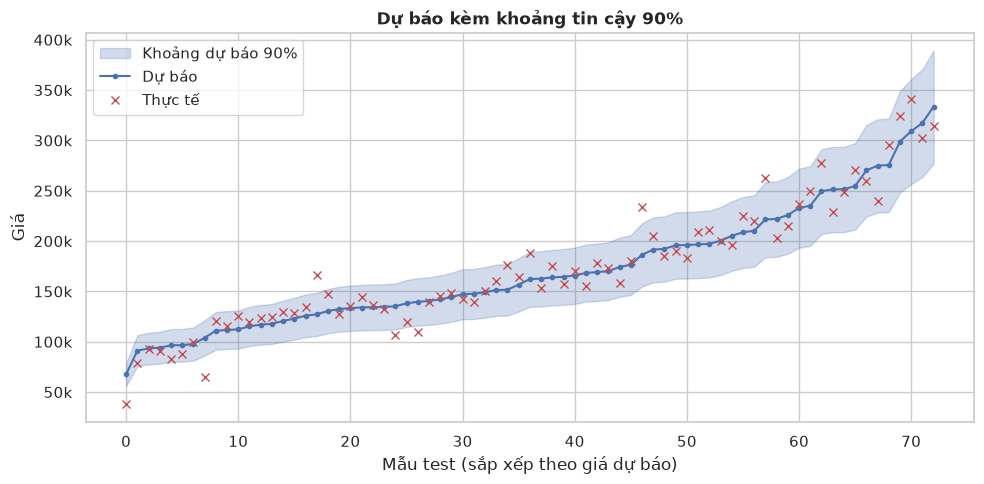

In [20]:
oof = cross_val_predict(clone(tuned[best_name]), X_train, y_train, cv=cv, n_jobs=-1)
oof_resid = y_train.values - oof
lo_q, hi_q = np.quantile(oof_resid, [0.05, 0.95])          # khoảng 90%

lower = np.expm1(pred_test + lo_q)
upper = np.expm1(pred_test + hi_q)
coverage = np.mean((y_true >= lower) & (y_true <= upper))

print(f"Khoảng dự báo 90%: giá thực tế nằm trong [dự báo × {np.exp(lo_q):.2f}, dự báo × {np.exp(hi_q):.2f}]")
print(f"Độ phủ thực tế trên tập test: {coverage:.1%} (mục tiêu 90%)")

idx = np.argsort(y_true)[::len(y_true) // 60]               # lấy mẫu thưa để vẽ cho dễ nhìn
order = idx[np.argsort(y_hat[idx])]
plt.figure(figsize=(10, 5))
plt.fill_between(range(len(order)), lower[order], upper[order], alpha=0.25, color="#4C72B0", label="Khoảng dự báo 90%")
plt.plot(y_hat[order], "o-", ms=3, color="#4C72B0", label="Dự báo")
plt.plot(y_true[order], "x", color="#C44E52", label="Thực tế")
plt.gca().yaxis.set_major_formatter(usd); plt.xlabel("Mẫu test (sắp xếp theo giá dự báo)"); plt.ylabel("Giá")
plt.title("Dự báo kèm khoảng tin cậy 90%"); plt.legend()
plt.tight_layout(); savefig("m06_interval.png"); plt.show()

## 10. Diễn giải mô hình

### 10.1 Permutation importance (trên tập test, theo biến gốc)

Xáo trộn từng biến gốc và đo mức tăng RMSLE: biến càng quan trọng thì sai số tăng càng nhiều. Cách này áp dụng được cho mọi mô hình (kể cả ensemble) và không bị thiên lệch bởi One-Hot như importance dựa trên cây.

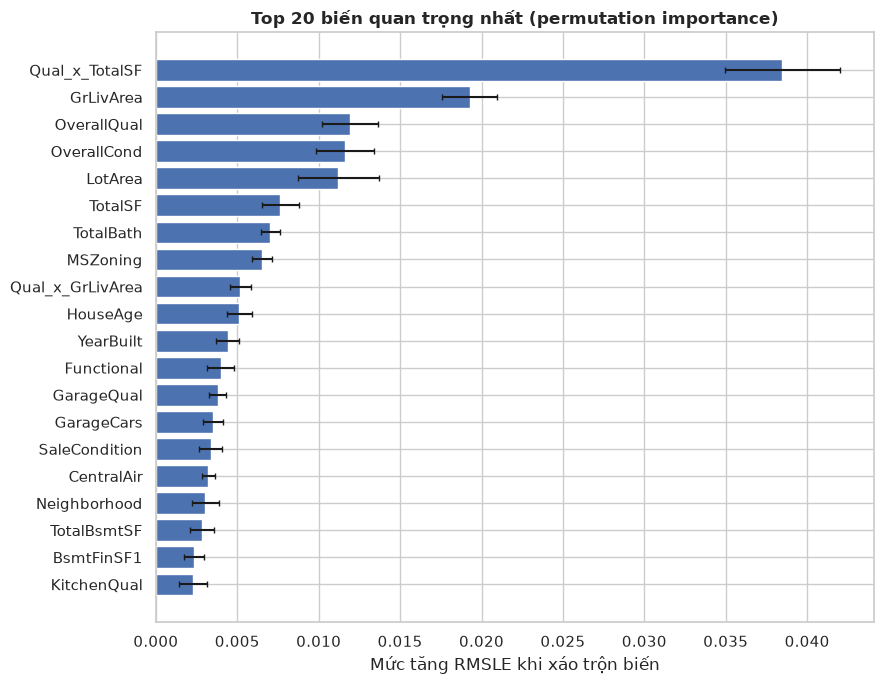

,importance,std
Qual_x_TotalSF,0.0385,0.0035
GrLivArea,0.0193,0.0017
OverallQual,0.0119,0.0017
OverallCond,0.0116,0.0018
LotArea,0.0112,0.0025
TotalSF,0.0076,0.0011
TotalBath,0.0070,0.0006
MSZoning,0.0065,0.0006
Qual_x_GrLivArea,0.0052,0.0007
HouseAge,0.0051,0.0008


In [21]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=15, random_state=SEED,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns)
imp = imp.sort_values("importance", ascending=False)

top = imp.head(20).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top.index, top["importance"], xerr=top["std"], color="#4C72B0", capsize=2)
plt.title("Top 20 biến quan trọng nhất (permutation importance)")
plt.xlabel("Mức tăng RMSLE khi xáo trộn biến")
plt.tight_layout(); savefig("m07_permutation_importance.png"); plt.show()

imp.head(15)

### 10.2 Hệ số của Lasso (mô hình tuyến tính dễ diễn giải)

Biến số đã được chuẩn hóa nên hệ số cho biết **giá (log) thay đổi bao nhiêu khi biến tăng 1 độ lệch chuẩn**; `exp(hệ số) − 1` xấp xỉ % thay đổi của giá. Lasso đưa nhiều hệ số về đúng 0 → tự động chọn biến.

Lasso giữ lại 112 / 223 đặc trưng (alpha = 0.00054)


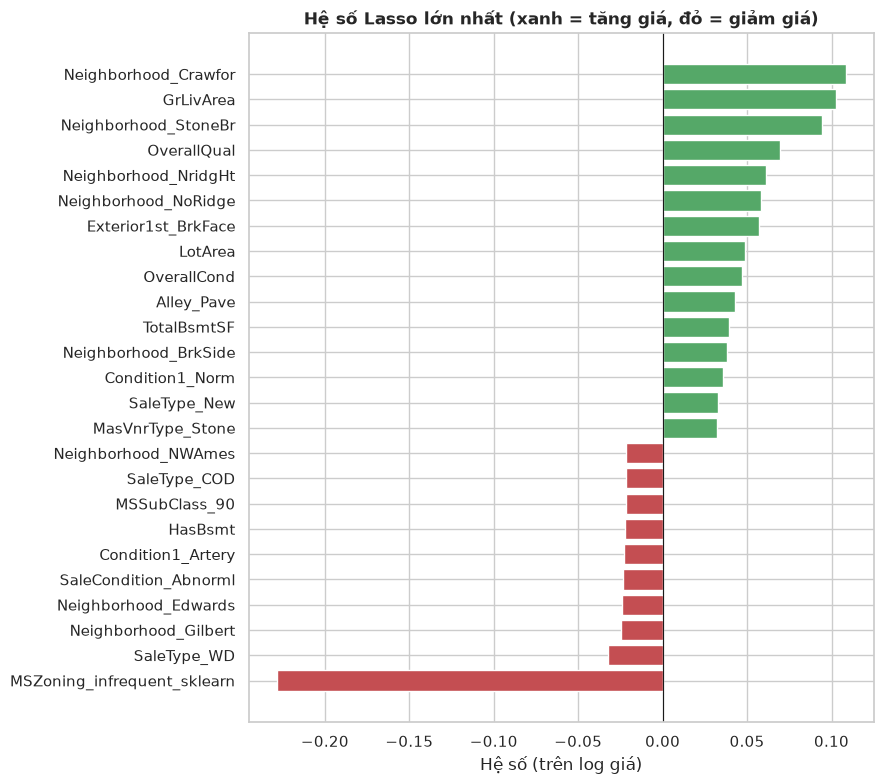

,hệ số,≈ % giá / 1 SD
Neighborhood_Crawfor,0.1083,11.4419
GrLivArea,0.1029,10.8388
Neighborhood_StoneBr,0.0942,9.8797
OverallQual,0.0695,7.1966
Neighborhood_NridgHt,0.0614,6.3315
Neighborhood_NoRidge,0.0583,5.9998
Exterior1st_BrkFace,0.0572,5.8919
LotArea,0.0491,5.0281
OverallCond,0.0468,4.7950
Alley_Pave,0.0427,4.3616


In [22]:
lasso_fit = clone(tuned["Lasso"]).fit(X_train, y_train)
names = lasso_fit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso_fit.named_steps["model"].coef_, index=names)

print(f"Lasso giữ lại {(coef != 0).sum()} / {len(coef)} đặc trưng (alpha = {lasso_fit.named_steps['model'].alpha:.5f})")

nz = coef[coef != 0]
show = pd.concat([nz.sort_values().head(10), nz.sort_values().tail(15)])
plt.figure(figsize=(9, 8))
plt.barh(show.index, show.values, color=np.where(show.values > 0, "#55A868", "#C44E52"))
plt.axvline(0, color="k", lw=0.8)
plt.title("Hệ số Lasso lớn nhất (xanh = tăng giá, đỏ = giảm giá)")
plt.xlabel("Hệ số (trên log giá)")
plt.tight_layout(); savefig("m08_lasso_coef.png"); plt.show()

pd.DataFrame({"hệ số": show, "≈ % giá / 1 SD": (np.exp(show) - 1) * 100}).sort_values("hệ số", ascending=False)

> **Lưu ý khi đọc:** với biến One-Hot, hệ số là chênh lệch so với các hạng mục còn lại (không phải 1 SD). Các cột `*_infrequent_sklearn` (ví dụ `MSZoning_infrequent_sklearn`) là nhóm gộp các hạng mục hiếm (< 10 mẫu), nên hệ số lớn của chúng dựa trên rất ít căn và cần đọc thận trọng. Vì Lasso chọn một biến đại diện trong nhóm biến tương quan, hệ số của từng biến riêng lẻ không ổn định bằng dự báo chung.

## 11. Lưu mô hình & hàm dự báo

Mô hình được lưu cùng toàn bộ bước tiền xử lý (một `Pipeline` duy nhất), nên khi dự báo chỉ cần đưa vào bảng đặc trưng **sau `engineer()`**. Khi nạp lại cần có file `custom_transformers.py` cùng thư mục.

In [23]:
# Huấn luyện lại trên TOÀN BỘ dữ liệu (train + test) để bản triển khai tận dụng tối đa dữ liệu.
# Hiệu năng kỳ vọng của bản này chính là số đo trên tập test ở bước 9.
deploy_model = clone(tuned[best_name]).fit(X, y)

bundle = {
    "model": deploy_model,
    "model_name": best_name,
    "feature_columns": X.columns.tolist(),
    "prediction_interval_log": (float(lo_q), float(hi_q)),   # khoảng 90% (xem 9.4)
    "test_metrics": res["Test"].to_dict(),
}
joblib.dump(bundle, os.path.join(OUT_DIR, "house_price_model.joblib"))
res.to_csv(os.path.join(OUT_DIR, "test_metrics.csv"))
compare.to_csv(os.path.join(OUT_DIR, "model_comparison_cv.csv"))
print("Đã lưu:", sorted(os.listdir(OUT_DIR)))


def predict_price(raw_df, bundle_path=os.path.join(OUT_DIR, "house_price_model.joblib")):
    # raw_df: DataFrame có cùng cột như cleaned.csv (đọc với keep_default_na=False, na_values=['', 'NA']).
    # Trả về giá dự báo và khoảng 90%.
    b = joblib.load(bundle_path)
    feats = engineer(raw_df.assign(SalePrice=np.nan))[b["feature_columns"]]
    p = b["model"].predict(feats)
    lo, hi = b["prediction_interval_log"]
    return pd.DataFrame({"Giá dự báo": np.expm1(p).round(-2),
                         "Thấp (90%)": np.expm1(p + lo).round(-2),
                         "Cao (90%)":  np.expm1(p + hi).round(-2)}, index=raw_df.index)

# Lưu ý: các căn này nằm trong dữ liệu huấn luyện của bản triển khai nên chỉ minh họa cách gọi hàm,
# KHÔNG phải số đo hiệu năng (hiệu năng thật: xem bảng test ở bước 9).
demo = raw.loc[~out_mask].sample(5, random_state=1)
predict_price(demo).assign(**{"Giá thực tế": demo["SalePrice"]})

Đã lưu: ['.ipynb_checkpoints', 'house_price_model.joblib', 'model_comparison_cv.csv', 'test_metrics.csv']


,Giá dự báo,Thấp (90%),Cao (90%),Giá thực tế
1163,"124,800.0000","103,600.0000","145,700.0000",108959
111,"171,400.0000","142,300.0000","200,100.0000",180000
1273,"178,200.0000","148,000.0000","208,000.0000",177000
1147,"182,000.0000","151,200.0000","212,500.0000",174500
368,"139,400.0000","115,700.0000","162,700.0000",132000


## 12. Kết luận

*(Số liệu dưới đây là kết quả của lần chạy với `SEED = 42`; chạy lại với phiên bản thư viện khác có thể lệch nhẹ.)*

### Kết quả chính

| | CV 5-fold (train) | Test (292 căn, chưa từng dùng) |
|---|---|---|
| RMSLE (log) | 0.109 | 0.120 |
| R² | 0.925 (log) | 0.939 (USD) |
| RMSE | – | ≈ 16.6k USD |
| MAE | – | ≈ 11.9k USD |
| Sai số % trung vị / trung bình (MAPE) | – | 5.2% / 8.1% |

- **Mô hình cuối:** ensemble trung bình (Voting) của Lasso, ElasticNet, Gradient Boosting và HistGradientBoosting, huấn luyện trên `log1p(SalePrice)`. So với mốc "luôn đoán giá trung bình" (RMSE ≈ 67.6k USD), sai số giảm khoảng 4 lần.
- **Chênh lệch giữa các mô hình nhỏ.** Ensemble (CV RMSLE 0.1092) chỉ hơn ElasticNet (0.1108) một chút, nằm trong độ lệch chuẩn của CV (≈ 0.007–0.009). Mô hình tuyến tính có regularization đã gần bằng boosting, nên nếu cần dễ diễn giải thì Lasso (test RMSLE 0.122) là lựa chọn hợp lý. Random Forest và HistGradientBoosting chưa tinh chỉnh bị overfit rõ (train RMSLE ≪ CV RMSLE).
- **Test kém CV một chút** (0.120 so với 0.109): do tập test nhỏ và việc chọn mô hình theo CV luôn hơi lạc quan. Sai số điển hình ngoài mẫu nên kỳ vọng ở mức 0.11–0.12 log, tức khoảng 11–12% giá.

### Trả lời lại câu hỏi của EDA: diện tích hay chất lượng?

Đo bằng sức dự báo ngoài mẫu (CV R², hồi quy tuyến tính trên log giá):

| Bộ biến | CV R² |
|---|---|
| Chỉ `GrLivArea` | 0.56 |
| Chỉ `OverallQual` | 0.68 |
| `GrLivArea` + `OverallQual` | 0.78 |
| `TotalSF` + `OverallQual` + tương tác | 0.81 |
| 11 biến "cốt lõi" (thêm tuổi nhà, garage, bếp, hầm, số phòng tắm…) | 0.88 |
| Toàn bộ 91 đặc trưng (Lasso) | 0.92 |

- Chất lượng đơn lẻ giải thích giá tốt hơn diện tích đơn lẻ, nhưng hai nhóm **bổ sung** cho nhau (0.56 / 0.68 → 0.78), đúng với dấu hiệu chồng lấn một phần mà EDA ghi nhận. Dùng `TotalSF` thay `GrLivArea` cải thiện đáng kể (→ 0.81).
- **Biến tương tác không giúp được nhiều như EDA gợi ý** trong mô hình tuyến tính trên log giá (`GrLivArea` + `OverallQual` 0.776 → thêm tương tác 0.777). Khi đã log hóa giá, quan hệ vốn đã mang tính nhân, nên phần lớn "tương tác" được hấp thụ. `Qual_x_TotalSF` vẫn đứng đầu permutation importance, nhưng nó tương quan mạnh với `TotalSF` và `OverallQual` nên không nên đọc đó như một hiệu ứng riêng.
- **`OverallCond` hóa ra quan trọng khi đã kiểm soát các biến khác** (hạng 4 theo permutation importance, hệ số Lasso dương), dù EDA thấy tương quan thô gần bằng 0. Nguyên nhân hợp lý là nhà cũ nhưng được giữ tình trạng tốt có giá cao hơn nhà cùng tuổi bị xuống cấp, điều mà tương quan thô bị `OverallQual` và `HouseAge` che mất. Đây vẫn chỉ là mối liên hệ, chưa phải nhân quả.
- **Vị trí quan trọng:** phần lớn các hệ số Lasso lớn nhất là `Neighborhood` (Crawford, StoneBr, NridgHt, NoRidge), xác nhận cảnh báo ở §10.4 của EDA rằng một phần "tác động" của diện tích/chất lượng thực ra là hiệu ứng khu vực.

### Hạn chế cần biết

1. **Nhà rẻ và chất lượng thấp dự báo kém hơn hẳn.** Phân khúc giá thấp nhất có MAPE 14.7% và thiên lệch +10% (dự báo cao hơn thực tế); nhóm `OverallQual` 1–4 có MAPE 18.9% (chỉ 22 căn trong test). Các dự báo sai nhiều nhất đều là nhà cũ giá thấp, nhiều căn là giao dịch không điển hình (`Abnorml`, `Family`), ví dụ một căn bán nội bộ gia đình giá 82.5k bị dự báo 174.5k. Các biến trong dữ liệu không cho biết quan hệ người mua–người bán hay tình trạng thật của căn nhà.
2. **Khoảng dự báo 90% có độ phủ 93.8%**, hơi thận trọng, nhưng độ rộng là cố định theo tỷ lệ (×0.83 đến ×1.17) nên có thể quá hẹp với nhà rẻ (sai số % lớn hơn) và quá rộng với nhà đắt.
3. **Phạm vi áp dụng:** dữ liệu chỉ gồm giao dịch ở Ames, Iowa trong 2006–2010; chia train/test ngẫu nhiên nên chưa kiểm tra khả năng dự báo theo thời gian và không nên dùng cho thị trường hay thời điểm khác. Tập test 292 căn (chỉ 10 căn `OverallQual` 9–10) nên các số đo theo nhóm nhỏ có độ bất định lớn.
4. Hệ số Lasso và importance chỉ phản ánh **mối liên hệ**, không phải nhân quả (ví dụ không thể suy ra "xây thêm 1 phòng tắm làm giá tăng X%").

### Hướng cải thiện tiếp theo

- Mã hóa `Neighborhood` bằng target encoding (trong CV) hoặc thêm đặc trưng vị trí/giá trung bình khu vực.
- Xử lý riêng giao dịch phi thị trường (`Abnorml`, `Family`, `Partial`): gắn cờ, giảm trọng số hoặc loại khi mục tiêu là ước lượng giá thị trường.
- Thử XGBoost / LightGBM / CatBoost và stacking với meta-learner (không dùng ở đây để notebook chỉ cần `scikit-learn`).
- Khoảng dự báo thích ứng theo phân khúc giá (conformal có điều kiện) và kiểm định theo thời gian (huấn luyện trên các năm đầu, kiểm tra trên năm cuối).